### Load Dataset 

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("sample_-_superstore.xls")
print("Dataset Loaded Successfully!")

df.head()

Dataset Loaded Successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


### Check customer segments

In [11]:
df['Segment'].value_counts()

Segment
Consumer       5281
Corporate      3090
Home Office    1823
Name: count, dtype: int64

### Compare segment performance

In [12]:
segment_analysis = df.groupby('Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()

segment_analysis

,Segment,Total_Sales,Total_Profit,Total_Orders
0,Consumer,1.170660e+06,136371.4463,2628
1,Corporate,7.158061e+05,94249.6400,1552
2,Home Office,4.400684e+05,61675.7283,931


### Calculate profit margin

In [13]:
segment_analysis['Profit_Margin'] = (
    segment_analysis['Total_Profit'] /
    segment_analysis['Total_Sales']
) * 100

segment_analysis

,Segment,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
0,Consumer,1.170660e+06,136371.4463,2628,11.649110
1,Corporate,7.158061e+05,94249.6400,1552,13.166923
2,Home Office,4.400684e+05,61675.7283,931,14.015031


### Create visualizations

#### Chart 1: Sales by Customer Segment

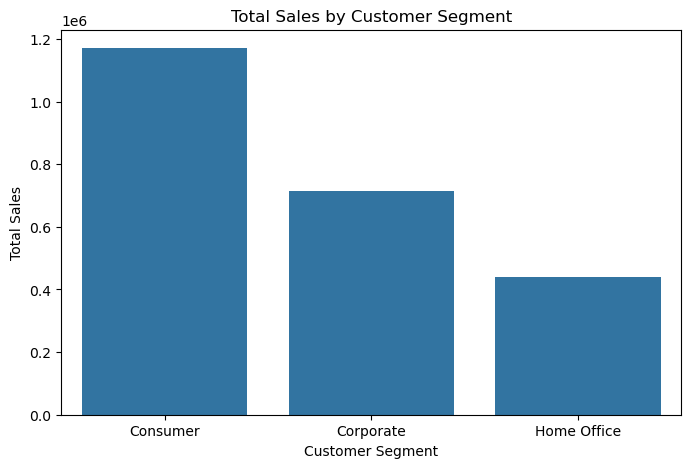

In [14]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=segment_analysis,
    x='Segment',
    y='Total_Sales'
)

plt.title('Total Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.show()

#### Chart 2: Profit by Customer Segment

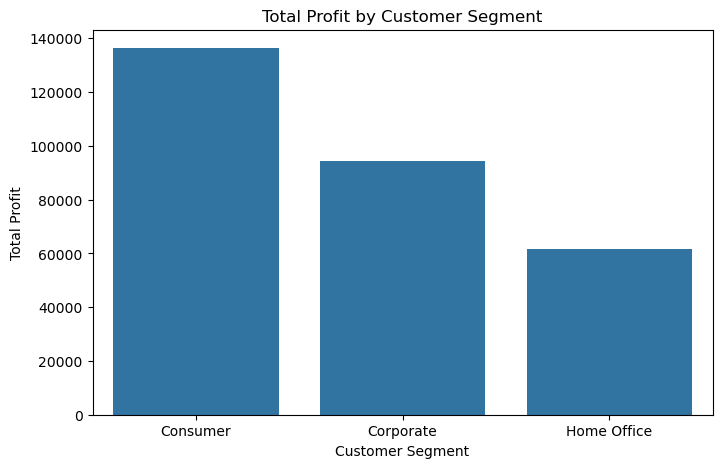

In [15]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=segment_analysis,
    x='Segment',
    y='Total_Profit'
)

plt.title('Total Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.show()

#### Chart 3: Orders by Customer Segment

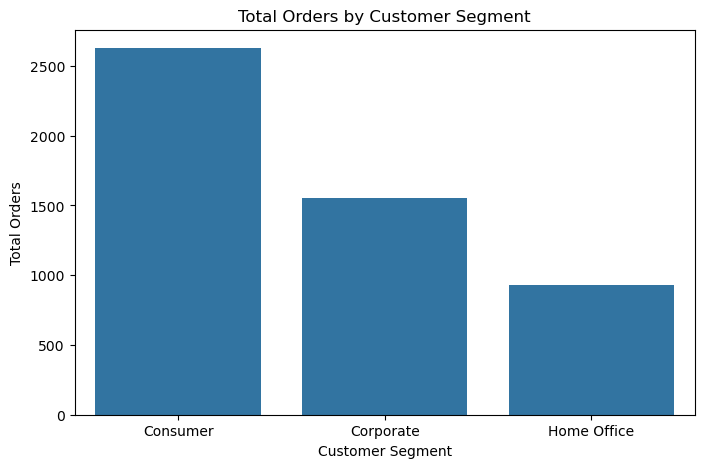

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=segment_analysis,
    x='Segment',
    y='Total_Orders'
)

plt.title('Total Orders by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Orders')
plt.show()